In [1]:
import os
from langchain.agents import create_agent
#from langchain_core.tools import tool -? used for @tool
from langchain_core.tools import Tool
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from langchain_astradb import AstraDBVectorStore
from langchain_groq import ChatGroq
from langchain_community.document_loaders import WebBaseLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import END
from langgraph.graph import StateGraph
from typing import Annotated, TypedDict, Sequence
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage
from langgraph.graph.message import add_messages

C:\Users\nihar\AppData\Local\Temp\ipykernel_25352\109102878.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import WikipediaQueryRun
USER_AGENT environment variable not set, consider setting it to identify your requests.


In [2]:
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

ASTRA_DB_API_ENDPOINT = ""
ASTRA_DB_APPLICATION_TOKEN = ""

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

vector_store = AstraDBVectorStore(
    collection_name="agentic_rag",
    embedding=embeddings,
    api_endpoint=ASTRA_DB_API_ENDPOINT,
    token=ASTRA_DB_APPLICATION_TOKEN,
    namespace=None,
)


model = ChatGroq(
    model="qwen/qwen3.8-27b",
    max_tokens=200,
    temperature=0
)

retriver = vector_store.as_retriever()

c:\Users\nihar\AgenticAIWorkSpace\AgenticAI\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1991.74it/s]


In [3]:
def retriever_tool_func(query: str) -> str:
    print("📚 Using RAGRetriever tool")
    docs = retriver.invoke(query)
    return "\n".join([doc.page_content for doc in docs])




In [4]:
#Retriver tools for vector database
retriever_tool=Tool(
    name="RAGRetriever",
    description="Use this tool to fetch relevant knowledge base info",
    func=retriever_tool_func
)


In [5]:
import wikipedia

# RAG Tool
retriever_tool = Tool(
    name="RAGRetriever",
    func=retriever_tool_func,
    description=(
        "Search ONLY the internal vector database. "
        "Use this tool when the user requests information "
        "from RAGRetriever, internal documents, or the knowledge base. "
        "Do not use it for questions explicitly assigned to Wikipedia."
    )
)

# Wikipedia Tool
wiki_tool = WikipediaQueryRun(
    api_wrapper=WikipediaAPIWrapper(
        top_k_results=1,
        doc_content_chars_max=500
    ),
    name="WikipediaSearch",
    description=(
        "Search Wikipedia for general encyclopedic information. "
        "Use this tool when the user explicitly requests Wikipedia "
        "or asks for general knowledge from Wikipedia."
    )
)

In [6]:
# ----------------------------
# 2. Define the Agent Node
# ----------------------------



tools = [retriever_tool,wiki_tool]

# Create the agent
agent = create_agent(
   model=model,
   tools=tools

)


In [7]:
# --------------------------
# 3. LangGraph Agent State
# --------------------------

class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]

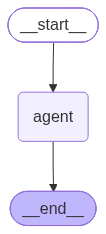

In [8]:
# --------------------------
# 4. Build LangGraph Graph
# --------------------------

builder = StateGraph(AgentState)

builder.add_node("agent", agent)
builder.set_entry_point("agent")
builder.add_edge("agent", END)

graph = builder.compile()
graph

In [9]:
from langchain_core.messages import AIMessage, ToolMessage

if __name__ == "__main__":
    user_query = "What is an agent loop form retriver tool and  then search wikipidea for what is machine learning?"

    state = {"messages": [HumanMessage(content=user_query)]}

    result = graph.invoke(state)

    print("\n========== TOOL EXECUTION HISTORY ==========")

    for msg in result["messages"]:

        if isinstance(msg, AIMessage) and msg.tool_calls:
            for call in msg.tool_calls:
                print(f"🔧 Tool Called: {call['name']}")
                print(f"📥 Input: {call['args']}")

        elif isinstance(msg, ToolMessage):
            print(f"✅ Tool Executed: {msg.name}")
            print(f"📤 Output: {str(msg.content)[:200]}")

    print("\n========== FINAL ANSWER ==========")
    print(result["messages"][-1].content)

APIConnectionError: Connection error.